# 31회 후기 유형 연습 해설

공식 원문·정답이 아닌 창작 합성 자료입니다. README와 출처·보완 명세를 먼저 확인하세요. Python 3.12 별도 실행 환경을 사용합니다. 아래 문제 지문은 PDF와 같으며 설명 셀의 선택 근거·가정·가설과 실행 출력의 계산값·기각 여부·상황 결론을 함께 읽으세요. `분석코드.py`로 같은 계산을 일괄 실행할 수 있습니다.

In [1]:
from pathlib import Path
import sys
FOLDER = Path(__file__).resolve().parent if '__file__' in globals() else Path.cwd()
repo = next(p for p in [FOLDER]+list(FOLDER.parents) if (p/'tools/exams').is_dir())
sys.path.insert(0,str(repo/'기출문제/유형연습/공통'))
from analysis import Context
ctx=Context(FOLDER)


## 1. 체형 분류와 별도 검진자료

obesity.csv는 height_cm·weight·activity·age와 3수준 body_class다. bmi는 정의상 타깃과 관계가 강하나 여기서는 예측 시 관측 가능하다고 가정한다. checkup.csv는 다른 청소년들의 검사 자료다. 모든 행은 독립 합성 자료이며 실제 임상 판정에 사용할 수 없다.

### 1-1

**문제** 체형 자료의 품질을 확인하고 BMI를 파생하시오. BMI 산식·키 단위와 예측 시 사용 가능성을 설명한 뒤 seed=31로 7:3 층화 분할하시오.

**풀이·선택 근거·해석**

키를 m로 바꿔 BMI=kg/m²를 계산한다. 타깃 결정 규칙을 흉내 낸 합성 연습이므로 일반화 성능이 실제 의료 성능을 뜻하지 않는다.

In [2]:
ctx.run('1-1', 'obesity_prepare')


=== 1-1 ===
BMI and missing
{
  "summary": [
    {
      "index": "count",
      "id": 240.0,
      "height_cm": 240.0,
      "weight": 240.0,
      "activity": 230.0,
      "age": 240.0,
      "body_class": 240.0,
      "BMI": 240.0
    },
    {
      "index": "mean",
      "id": 120.5,
      "height_cm": 169.46753947916665,
      "weight": 67.42169196,
      "activity": 2.4,
      "age": 40.40833333333333,
      "body_class": 1.0541666666666667,
      "BMI": 23.614710252308228
    },
    {
      "index": "std",
      "id": 69.42621983083913,
      "height_cm": 8.50179657862957,
      "weight": 15.288977953823636,
      "activity": 1.1506595792192007,
      "age": 13.641860161834048,
      "body_class": 0.8086763639712404,
      "BMI": 5.707377687986657
    },
    {
      "index": "min",
      "id": 1.0,
      "height_cm": 147.242097,
      "weight": 17.2503758,
      "activity": 1.0,
      "age": 18.0,
      "body_class": 0.0,
      "BMI": 6.1452397513379955
    },
    {
      "inde

### 1-2

**문제** 학습 폴드 안에서 전처리하는 분류 파이프라인과 제한된 튜닝을 구성하시오. 학습 내부 CV의 macro-F1으로 설정을 선택하고 보류 macro-F1·혼동행렬을 보고하시오.

**풀이·선택 근거·해석**

3-fold CV 안에서 median 대치·표준화와 Logistic C=[0.1,1,10] 탐색을 수행한다. 보류 자료로 설정을 고르지 않는다.

In [3]:
ctx.run('1-2', 'obesity_model')


=== 1-2 ===
tuning
{
  "best": {
    "model__C": 10.0
  },
  "CV": 0.9705614205614205,
  "holdout_macro_F1": 0.9723787809697523,
  "confusion": [
    [
      21,
      1,
      0
    ],
    [
      0,
      24,
      1
    ],
    [
      0,
      0,
      25
    ]
  ]
}


### 1-3

**문제** checkup의 검사일-생년월일 차이를 365일로 나눈 몫을 연령으로 정의하고 BMI와 suitable을 생성하시오. 연령 16/17세·성별별 허용 BMI 구간은 기준표.json을 사용하며 경계·범위 밖을 검증하시오.

**풀이·선택 근거·해석**

실제 달력 만 나이와 다른 시험용 근사 규칙이다. 하한 초과·상한 이하를 적용한다. 범위 밖 연령은 명시적으로 오류 처리한다.

In [4]:
ctx.run('1-3', 'checkup_features')


=== 1-3 ===
engineered
[
  {
    "index": 0,
    "id": 1,
    "age": 16,
    "gender": "M",
    "BMI": 15.48807010194536,
    "suitable": 0
  },
  {
    "index": 1,
    "id": 2,
    "age": 16,
    "gender": "F",
    "BMI": 24.912848174242708,
    "suitable": 0
  },
  {
    "index": 2,
    "id": 3,
    "age": 16,
    "gender": "F",
    "BMI": 23.757545145339098,
    "suitable": 1
  },
  {
    "index": 3,
    "id": 4,
    "age": 17,
    "gender": "F",
    "BMI": 20.648515999531515,
    "suitable": 1
  },
  {
    "index": 4,
    "id": 5,
    "age": 17,
    "gender": "M",
    "BMI": 20.23024246449856,
    "suitable": 1
  },
  {
    "index": 5,
    "id": 6,
    "age": 17,
    "gender": "F",
    "BMI": 27.868045370585357,
    "suitable": 0
  },
  {
    "index": 6,
    "id": 7,
    "age": 17,
    "gender": "F",
    "BMI": 13.592488063112484,
    "suitable": 0
  },
  {
    "index": 7,
    "id": 8,
    "age": 17,
    "gender": "F",
    "BMI": 20.896958028856364,
    "suitable": 1
  },
  {
    

### 1-4

**문제** 적절체중 여부와 exercise·sleep의 관계를 학습 구간에서 검정하시오. 가설·p-value·다중비교 판단을 제시하고, 보정 후 유의한 변수만 포함하는 후속 분석의 한계를 설명하시오.

**풀이·선택 근거·해석**

고정 행 분할 후 훈련 자료에서만 독립성 검정을 하고 Holm 보정한다. 데이터 기반 선택 후 일반 계수 검정의 명목 유의수준은 보장되지 않는다.

In [5]:
ctx.run('1-4', 'checkup_select')


=== 1-4 ===
exercise_table
[
  {
    "exercise": 0,
    "0": 45,
    "1": 50
  },
  {
    "exercise": 1,
    "0": 41,
    "1": 56
  }
]
exercise_expected
[
  [
    42.552083333333336,
    52.447916666666664
  ],
  [
    43.447916666666664,
    53.552083333333336
  ]
]
{
  "method": "Pearson independence exercise-suitable",
  "H0": "exercise independent of suitable",
  "H1": "exercise associated with suitable",
  "statistic": 0.5048906039407189,
  "p_value": 0.47735907924375376,
  "df": 1,
  "alpha": 0.05,
  "reject_H0": false,
  "conclusion": "유의수준 5%에서 exercise와 suitable의 관련성에 대한 근거가 충분하지 않다.",
  "adjusted_p_value": 0.47735907924375376
}
sleep_table
[
  {
    "sleep": 0,
    "0": 57,
    "1": 47
  },
  {
    "sleep": 1,
    "0": 29,
    "1": 59
  }
]
sleep_expected
[
  [
    46.583333333333336,
    57.416666666666664
  ],
  [
    39.416666666666664,
    48.583333333333336
  ]
]
{
  "method": "Pearson independence sleep-suitable",
  "H0": "sleep independent of suitable",
  "H1": "slee

### 1-5

**문제** 두 관계 검정에서 보정 후 유의한 변수만 이용해 Logistic과 트리 앙상블을 비교하시오. 아무 변수도 남지 않으면 상수확률 기준모형으로 처리하시오. 같은 보류 자료에서 최종 ROC·AUC와 계수/오즈비를 보고하시오.

**풀이·선택 근거·해석**

특성 선택을 훈련 구간 안에서 완료한다. selected 변수를 CV에 고정한 경우 선택까지 중첩한 CV는 아니므로 CV 점수의 한계를 명시하고 최종 보류를 독립으로 유지한다.


=== 1-5 ===
CV selection
{
  "scores": {
    "Logistic": 0.6005597612082506,
    "RF": 0.6005597612082506
  },
  "chosen": "Logistic",
  "metric": "f1",
  "selection": "training CV only"
}


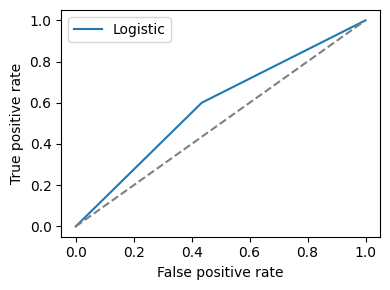

holdout
{
  "F1": 0.6,
  "confusion_matrix": [
    [
      13,
      10
    ],
    [
      10,
      15
    ]
  ],
  "classification_report": {
    "0": {
      "precision": 0.5652173913043478,
      "recall": 0.5652173913043478,
      "f1-score": 0.5652173913043478,
      "support": 23.0
    },
    "1": {
      "precision": 0.6,
      "recall": 0.6,
      "f1-score": 0.6,
      "support": 25.0
    },
    "accuracy": 0.5833333333333334,
    "macro avg": {
      "precision": 0.5826086956521739,
      "recall": 0.5826086956521739,
      "f1-score": 0.5826086956521739,
      "support": 48.0
    },
    "weighted avg": {
      "precision": 0.5833333333333334,
      "recall": 0.5833333333333334,
      "f1-score": 0.5833333333333334,
      "support": 48.0
    }
  },
  "n": 48,
  "AUC": 0.582608695652174
}
Logistic odds ratios (scaled numeric units)
[
  [
    1.5528700160948767
  ]
]
split IDs
{
  "train_index": [
    0,
    1,
    2,
    3,
    5,
    6,
    7,
    8,
    10,
    11,
    12,


In [6]:
ctx.run('1-5', 'checkup_models')

## 2. 제조·광고·발생 건수

제품 관측 x는 알려진 분산 144의 정규분포 N(theta,144)이고 theta의 사전분포는 N(90,225)다. 새 제품 한 개의 무게는 108이다. ads.csv는 독립 사업단위의 광고비와 매출이다. 접수 건수는 독립·동일률 포아송 과정이라고 가정한다. 이 수치들은 창작 연습 조건이다.

### 2-1

**문제** 제품 무게 관측 후 theta의 사후분포 평균·분산·95% 신용구간을 계산하시오. 평균이 사전평균과 관측값 사이에 놓이는 이유와 신용구간의 의미를 설명하시오.

**풀이·선택 근거·해석**

정규-정규 결합에서 정밀도를 합한다. 사후분산=(1/225+1/144)^-1, 사후평균은 정밀도 가중 평균이다. 신용구간을 반복표집 신뢰구간과 구분한다.

In [7]:
ctx.run('2-1', 'bayes')


=== 2-1 ===
posterior
{
  "mean": 100.97560975609754,
  "variance": 87.80487804878048,
  "credible95": [
    82.60991283818942,
    119.34130667400566
  ]
}


### 2-2

**문제** 광고비 TV·radio·paper로 sales를 설명하시오. 전체 모형의 가설·F·p-value·기각 여부, 계수 및 잔차 진단·VIF를 제시하시오.

**풀이·선택 근거·해석**

독립 정규 오차·선형 평균 작업 모형이다. 전체 F와 계수별 t, 잔차 검정은 서로 다른 가설이다. VIF가 낮아도 인과적 식별은 보장되지 않는다.


=== 2-2 ===
coefficients
[
  {
    "index": "const",
    "coef": 3.4275114168195753,
    "SE": 0.26164538544105215,
    "t": 13.099835149172858,
    "p": 7.864536295128767e-30
  },
  {
    "index": "TV",
    "coef": 0.04827305401744198,
    "SE": 0.0010749718733875182,
    "t": 44.90634147042465,
    "p": 1.3372244797118414e-117
  },
  {
    "index": "radio",
    "coef": 0.173827590593429,
    "SE": 0.005518345233818216,
    "t": 31.499948486034718,
    "p": 1.693700433502044e-86
  },
  {
    "index": "paper",
    "coef": 0.00020556176661195788,
    "SE": 0.0028872955652111624,
    "t": 0.07119526282267681,
    "p": 0.9433026466939747
  }
]
fit
{
  "R2": 0.9232750463343931,
  "n": 240.0
}
{
  "method": "OLS overall F",
  "H0": "all slopes=0",
  "H1": "at least one slope != 0",
  "statistic": 946.6407842771596,
  "p_value": 3.1268883155699245e-131,
  "df": [
    3.0,
    236.0
  ],
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 전체 설명변수와 평균 반응의 선형 연관성에 대한 근거가 있다."
}
VI

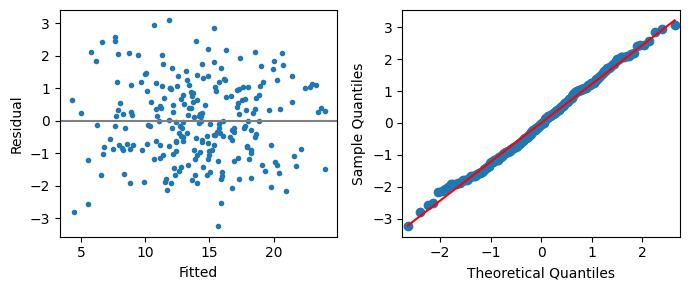

In [8]:
ctx.run('2-2', 'ads_full')

### 2-3

**문제** 광고 변수의 제거 기준을 5%로 미리 정하고 가장 큰 비유의 p-value 변수를 하나씩 제거해 재적합하시오. 과정·최종 식·VIF와 선택 후 추론의 한계를 설명하시오.

**풀이·선택 근거·해석**

후진 제거의 실행 순서를 기록한다. 같은 자료로 선택하고 검정한 계수 p값은 확증적 추론으로 해석하지 않는다.

In [9]:
ctx.run('2-3', 'ads_backward')


=== 2-3 ===
backward history
[
  {
    "remove": "paper",
    "p": 0.9433026466939747
  }
]
coefficients
[
  {
    "index": "const",
    "coef": 3.4376277283253067,
    "SE": 0.2192382365984724,
    "t": 15.679873099058028,
    "p": 1.713847704602961e-38
  },
  {
    "index": "TV",
    "coef": 0.048274407692953866,
    "SE": 0.0010725453115313945,
    "t": 45.009201172141644,
    "p": 4.1628105077378635e-118
  },
  {
    "index": "radio",
    "coef": 0.17383829796599629,
    "SE": 0.005504704519734813,
    "t": 31.57995081166879,
    "p": 6.832458312654556e-87
  }
]
fit
{
  "R2": 0.9232733984496719,
  "n": 240.0
}
{
  "method": "OLS overall F",
  "H0": "all slopes=0",
  "H1": "at least one slope != 0",
  "statistic": 1425.9447897548434,
  "p_value": 7.346771761638036e-133,
  "df": [
    2.0,
    237.0
  ],
  "alpha": 0.05,
  "reject_H0": true,
  "conclusion": "유의수준 5%에서 전체 설명변수와 평균 반응의 선형 연관성에 대한 근거가 있다."
}
VIF
{
  "const": 7.649799434197501,
  "TV": 1.004163839840618,
  "radio": 1.00

### 2-4

**문제** 시간당 평균 접수 2.4건인 안정된 독립 도착 과정에서 0건 및 2건 이상 확률을 구하시오. 포아송 가정을 어기는 과산포·시간대 효과가 있으면 무엇을 재검토할지 설명하시오.

**풀이·선택 근거·해석**

Poisson(2.4)의 pmf(0)와 sf(1)을 사용한다. 평균 도착률의 시간 균질성과 독립 증가량이 가정이며 관측 평균 하나만으로 분포가 확인되지 않는다.

In [10]:
ctx.run('2-4', 'poisson_probability')


=== 2-4 ===
Poisson(2.4)
{
  "p0": 0.09071795328941251,
  "p_ge2": 0.6915589588159976
}
